# Network Intrusion Detection on the NSL-KDD Dataset
### An Explainable Ensemble Learning Framework (Random Forest + XGBoost + SHAP)

**Research context:** *Trust and Transparency in AI-Based Network Intrusion Detection Systems*

This notebook implements a complete, reproducible pipeline for binary network intrusion detection (`normal` vs `anomaly`) using the **NSL-KDD** dataset (`KDDTrain+.arff`, `KDDTest+.arff`), the improved successor to the original KDD Cup 1999 dataset (duplicate records removed, more balanced class distribution).

**Pipeline stages**
1. Data loading (custom ARFF parser — robust to the malformed `@attribute` quoting in the public NSL-KDD ARFF release)
2. Exploratory Data Analysis (EDA)
3. Preprocessing (categorical encoding, feature scaling, train/test alignment)
4. Model training — Random Forest (baseline) and XGBoost (proposed/primary model)
5. Evaluation — Accuracy, Precision, Recall, F1-score, ROC-AUC, Confusion Matrix
6. **Explainable AI (XAI) layer** — SHAP (SHapley Additive exPlanations) for global and local model transparency

> Place `KDDTrain+.arff` and `KDDTest+.arff` in the same directory as this notebook before running.


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix, classification_report,
                              roc_curve)

from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

TRAIN_PATH = 'KDDTrain+.arff'
TEST_PATH  = 'KDDTest+.arff'

print('Libraries loaded successfully.')

Libraries loaded successfully.


## Google Colab Setup

This notebook is configured for Google Colab. The next cell installs Java and the Python-Weka bridge automatically. You do not need to install Weka manually on your computer.


In [ ]:
# Install Java and python-weka-wrapper3 for Google Colab
!apt-get update -qq
!apt-get install -y default-jre -qq
!pip install -q python-weka-wrapper3
print('Java and python-weka-wrapper3 installation completed.')


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package at-spi2-common.
(Reading database ... 126952 files and directories currently installed.)
Preparing to unpack .../00-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../01-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../02-libxtst6_2%3a1.2.3-1.1build1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1b

In [ ]:
import os
import zipfile  # Import zipfile
from google.colab import files

required_files = ['KDDTrain+.arff', 'KDDTest+.arff']
missing = [f for f in required_files if not os.path.exists('/content/' + f)]
if missing:
    print('Please select:', ', '.join(missing))
    uploaded = files.upload()
    print('Uploaded:', list(uploaded.keys()))

    # Unzip the uploaded files if they are zip archives
    for filename in uploaded.keys():
        if filename.endswith('.zip'):
            with zipfile.ZipFile(os.path.join('/content/', filename), 'r') as zf:
                # Extract to the /content/ directory
                zf.extractall('/content/')
            print(f'Extracted {filename} to /content/')
else:
    print('NSL-KDD files already exist in /content/. Skipping upload.')

for f in required_files:
    if not os.path.exists('/content/' + f):
        raise FileNotFoundError(f'Missing {f}. Upload both KDDTrain+.arff and KDDTest+.arff.')
print('Both NSL-KDD files are ready.')

Please select: KDDTrain+.arff, KDDTest+.arff


Saving KDDTrain+.arff.zip to KDDTrain+.arff (1).zip
Saving KDDTest+.arff.zip to KDDTest+.arff (1).zip
Uploaded: ['KDDTrain+.arff (1).zip', 'KDDTest+.arff (1).zip']
Extracted KDDTrain+.arff (1).zip to /content/
Extracted KDDTest+.arff (1).zip to /content/
Both NSL-KDD files are ready.


## 1. Data Loading

The public NSL-KDD `.arff` files ship with a formatting quirk in the `protocol_type` attribute line
(`{'tcp','udp', 'icmp'}` — inconsistent quoting/spacing) that breaks `scipy.io.arff.loadarff`.
The loader below parses the `@attribute` block for column names and reads the `@data` block directly
as CSV, which is fully robust to this issue.

In [ ]:
def load_nslkdd_arff(path: str) -> pd.DataFrame:
    """Robust loader for the NSL-KDD .arff files."""
    columns = []
    data_start_idx = None

    with open(path, 'r') as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        stripped = line.strip()
        if stripped.lower().startswith('@attribute'):
            col_name = line.split()[1].strip("'")
            columns.append(col_name)
        if stripped.lower() == '@data':
            data_start_idx = i + 1
            break

    if data_start_idx is None:
        raise ValueError(f"Could not find @data section in {path}")

    df = pd.read_csv(path, skiprows=data_start_idx, header=None, names=columns)
    return df


train_df = load_nslkdd_arff(TRAIN_PATH)
test_df  = load_nslkdd_arff(TEST_PATH)

print(f"Train set : {train_df.shape[0]:,} records  x  {train_df.shape[1]} columns")
print(f"Test set  : {test_df.shape[0]:,} records  x  {test_df.shape[1]} columns")
train_df.head()

Train set : 125,973 records  x  42 columns
Test set  : 22,544 records  x  42 columns


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


## 2. Exploratory Data Analysis (EDA)

In [ ]:
print("Missing values (train):", train_df.isnull().sum().sum())
print("Missing values (test) :", test_df.isnull().sum().sum())
print()
print("Class distribution (train):")
print(train_df['class'].value_counts())
print()
print("Class distribution (test):")
print(test_df['class'].value_counts())

Missing values (train): 0
Missing values (test) : 0

Class distribution (train):
class
normal     67343
anomaly    58630
Name: count, dtype: int64

Class distribution (test):
class
anomaly    12833
normal      9711
Name: count, dtype: int64


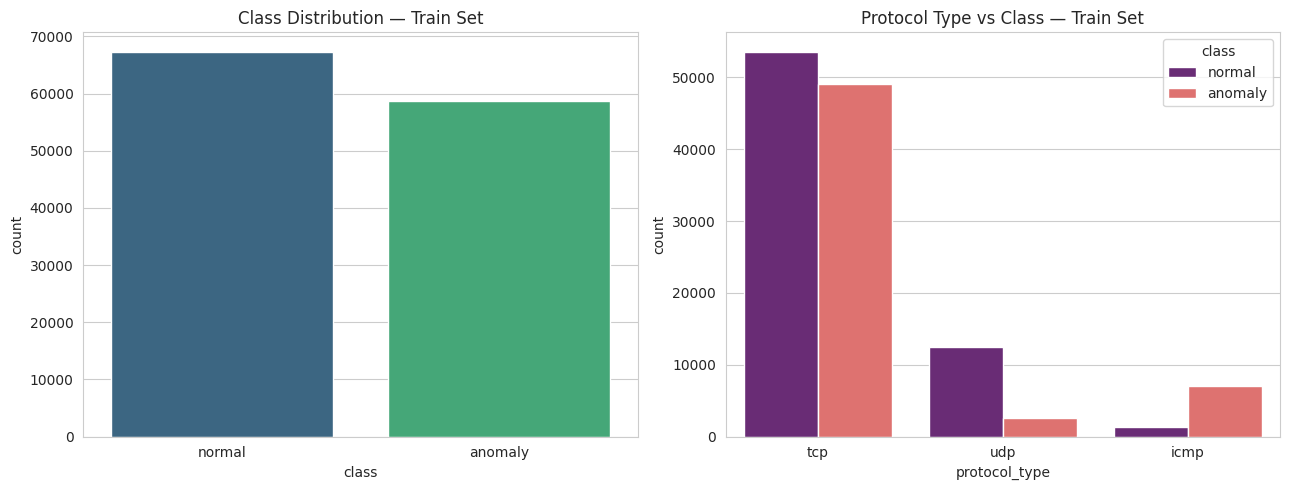

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(x='class', data=train_df, ax=axes[0], palette='viridis')
axes[0].set_title('Class Distribution — Train Set')

sns.countplot(x='protocol_type', hue='class', data=train_df, ax=axes[1], palette='magma')
axes[1].set_title('Protocol Type vs Class — Train Set')

plt.tight_layout()
plt.show()

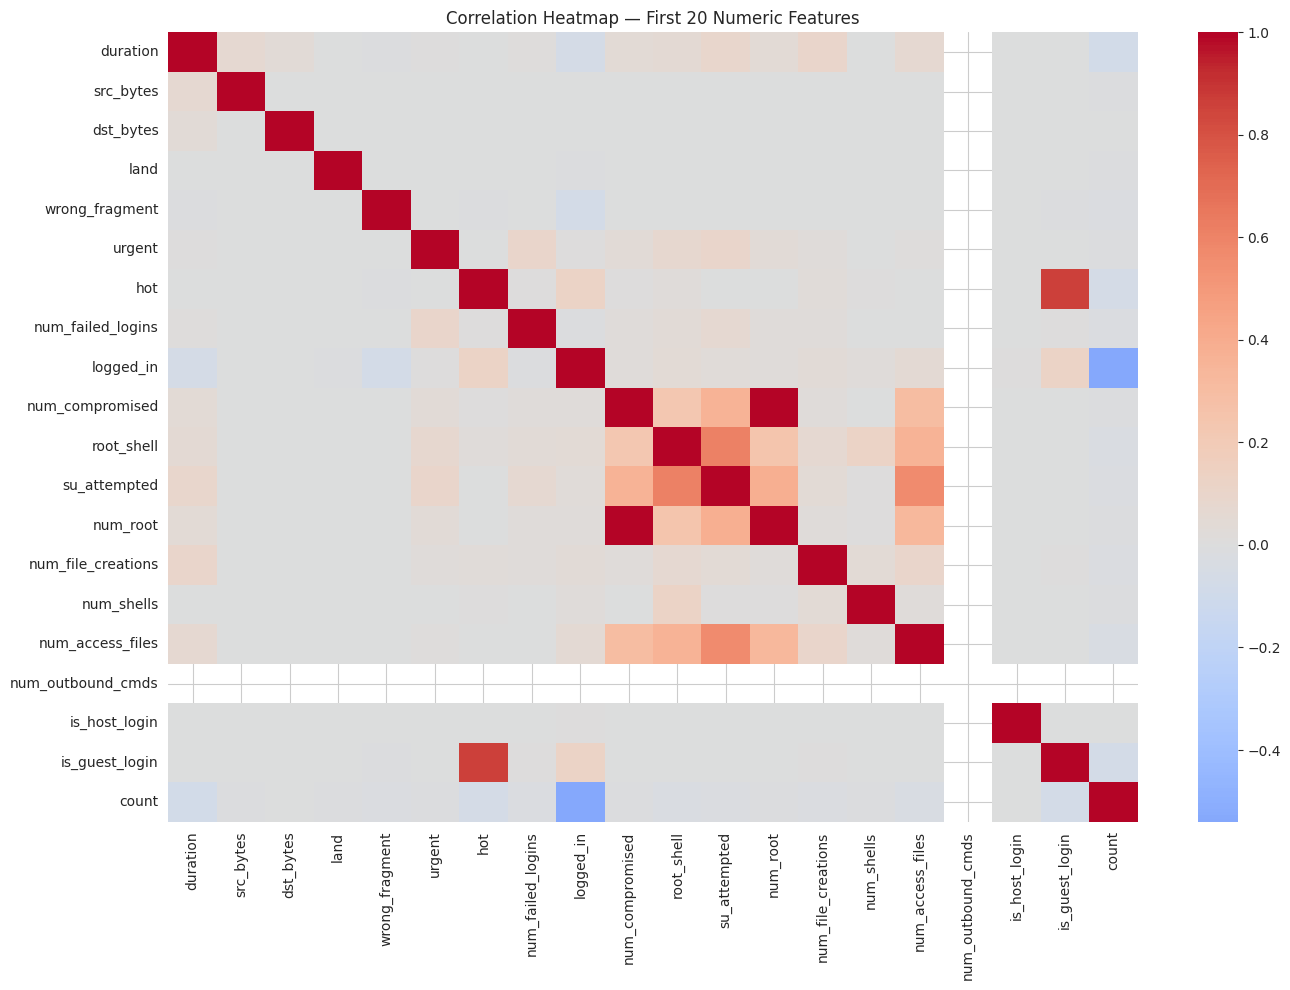

In [ ]:
plt.figure(figsize=(14, 10))
numeric_cols = train_df.select_dtypes(include=[np.number]).columns[:20]
corr = train_df[numeric_cols].corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap — First 20 Numeric Features')
plt.tight_layout()
plt.show()

## 3. Preprocessing

Steps:
1. **Target encoding** — `normal` → 0, `anomaly` → 1
2. **Categorical feature encoding** — `protocol_type`, `service`, `flag` are label-encoded. The encoder
   is fit on the **union** of train + test categories so that any service/flag value that appears only
   in the test set does not break `transform()` (a common failure point in NSL-KDD pipelines, since the
   test set contains a few service categories absent from train).
3. **Feature scaling** — `StandardScaler` fit on the training set only, applied to both splits (avoids
   data leakage).

In [ ]:
CATEGORICAL_COLS = ['protocol_type', 'service', 'flag']
TARGET_COL = 'class'

train_df['label'] = train_df[TARGET_COL].apply(lambda x: 0 if x == 'normal' else 1)
test_df['label']  = test_df[TARGET_COL].apply(lambda x: 0 if x == 'normal' else 1)

encoders = {}
for col in CATEGORICAL_COLS:
    le = LabelEncoder()
    combined_values = pd.concat([train_df[col], test_df[col]], axis=0).unique()
    le.fit(combined_values)
    train_df[col] = le.transform(train_df[col])
    test_df[col]  = le.transform(test_df[col])
    encoders[col] = le

feature_cols = [c for c in train_df.columns if c not in [TARGET_COL, 'label']]

X_train = train_df[feature_cols].copy()
y_train = train_df['label'].copy()
X_test  = test_df[feature_cols].copy()
y_test  = test_df['label'].copy()

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

print(f"Feature matrix — train: {X_train_scaled.shape}, test: {X_test_scaled.shape}")
print(f"Class balance — train: {y_train.mean():.3f} anomaly | test: {y_test.mean():.3f} anomaly")

Feature matrix — train: (125973, 41), test: (22544, 41)
Class balance — train: 0.465 anomaly | test: 0.569 anomaly


## 4. Model Training

Two models are trained and compared:

| Model | Role | Why |
|---|---|---|
| **Random Forest** | Baseline | Strong, well-understood bagging ensemble; robust to noisy/irrelevant NSL-KDD features |
| **XGBoost** | Proposed / primary model | Gradient-boosted trees — state-of-the-art on tabular intrusion-detection data in the literature, and natively supported by SHAP's fast `TreeExplainer` for the explainability layer below |


In [ ]:
results = {}

def evaluate_model(name, model, X_te, y_te, y_pred, y_proba):
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred)
    rec  = recall_score(y_te, y_pred)
    f1   = f1_score(y_te, y_pred)
    auc  = roc_auc_score(y_te, y_proba)
    results[name] = {'Accuracy': acc, 'Precision': prec, 'Recall': rec,
                      'F1-Score': f1, 'ROC-AUC': auc}
    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print()
    print(classification_report(y_te, y_pred, target_names=['normal', 'anomaly']))
    return results[name]

In [ ]:
# --- Random Forest (baseline) ---
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=RANDOM_STATE
)
rf_model.fit(X_train_scaled, y_train)

rf_pred  = rf_model.predict(X_test_scaled)
rf_proba = rf_model.predict_proba(X_test_scaled)[:, 1]

_ = evaluate_model('Random Forest', rf_model, X_test_scaled, y_test, rf_pred, rf_proba)

--- Random Forest ---
Accuracy : 0.7741
Precision: 0.9669
Recall   : 0.6245
F1-Score : 0.7589
ROC-AUC  : 0.9645

              precision    recall  f1-score   support

      normal       0.66      0.97      0.79      9711
     anomaly       0.97      0.62      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.84      0.77      0.77     22544



In [ ]:
# --- XGBoost (proposed / primary model) ---
original_xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
original_xgb_model.fit(X_train_scaled, y_train)

xgb_pred  = original_xgb_model.predict(X_test_scaled)
xgb_proba = original_xgb_model.predict_proba(X_test_scaled)[:, 1]

_ = evaluate_model('Original XGBoost', original_xgb_model, X_test_scaled, y_test, xgb_pred, xgb_proba)


--- Original XGBoost ---
Accuracy : 0.7988
Precision: 0.9681
Recall   : 0.6687
F1-Score : 0.7910
ROC-AUC  : 0.9724

              precision    recall  f1-score   support

      normal       0.69      0.97      0.81      9711
     anomaly       0.97      0.67      0.79     12833

    accuracy                           0.80     22544
   macro avg       0.83      0.82      0.80     22544
weighted avg       0.85      0.80      0.80     22544



In [ ]:
# --- Tuned XGBoost: validation-based hyperparameter + threshold optimization ---
# The original XGBoost is preserved above. This experiment uses only the training set
# for model/threshold selection, then evaluates once on the untouched NSL-KDD test set.
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
import numpy as np, pandas as pd, time

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_scaled, np.asarray(y_train).astype(int),
    test_size=0.20, stratify=np.asarray(y_train).astype(int), random_state=RANDOM_STATE
)

candidate_params = [
    dict(n_estimators=450, max_depth=5, learning_rate=0.06, min_child_weight=1,
         subsample=0.90, colsample_bytree=0.90, gamma=0.0, reg_lambda=1.0),
    dict(n_estimators=450, max_depth=6, learning_rate=0.05, min_child_weight=2,
         subsample=0.90, colsample_bytree=0.90, gamma=0.0, reg_lambda=1.5),
    dict(n_estimators=350, max_depth=4, learning_rate=0.08, min_child_weight=1,
         subsample=0.95, colsample_bytree=0.90, gamma=0.0, reg_lambda=1.0),
]

best_val_acc = -1
best_cfg = None
best_val_model = None
for i, params in enumerate(candidate_params, 1):
    model = XGBClassifier(
        **params, objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1
    )
    t0 = time.time()
    model.fit(X_tr, y_tr)
    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.50).astype(int)
    acc = accuracy_score(y_val, val_pred)
    print(f'Candidate {i}: validation accuracy={acc:.4f}, time={time.time()-t0:.1f}s')
    if acc > best_val_acc:
        best_val_acc, best_cfg, best_val_model = acc, params, model

# Refit the selected configuration on the complete training set.
tuned_xgb_model = XGBClassifier(
    **best_cfg, objective='binary:logistic', eval_metric='logloss',
    tree_method='hist', random_state=RANDOM_STATE, n_jobs=-1
)
t0 = time.time()
tuned_xgb_model.fit(X_train_scaled, np.asarray(y_train).astype(int))
print('Selected configuration:', best_cfg)
print(f'Final tuned-model training time: {time.time()-t0:.1f}s')

# Select the classification threshold on the validation set only (no test-set leakage).
val_prob = best_val_model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.30, 0.701, 0.01)
val_accs = [accuracy_score(y_val, (val_prob >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(val_accs))])
print(f'Validation-selected threshold: {best_threshold:.2f} (validation accuracy={max(val_accs):.4f})')

tuned_xgb_proba = tuned_xgb_model.predict_proba(X_test_scaled)[:, 1]
tuned_xgb_pred = (tuned_xgb_proba >= best_threshold).astype(int)
_ = evaluate_model('Tuned XGBoost', tuned_xgb_model, X_test_scaled, y_test, tuned_xgb_pred, tuned_xgb_proba)

# Use the tuned model for the later SHAP/XAI section.
xgb_model = tuned_xgb_model
xgb_pred = tuned_xgb_pred
xgb_proba = tuned_xgb_proba


Candidate 1: validation accuracy=0.9993, time=7.3s
Candidate 2: validation accuracy=0.9992, time=6.7s
Candidate 3: validation accuracy=0.9993, time=5.2s
Selected configuration: {'n_estimators': 450, 'max_depth': 5, 'learning_rate': 0.06, 'min_child_weight': 1, 'subsample': 0.9, 'colsample_bytree': 0.9, 'gamma': 0.0, 'reg_lambda': 1.0}
Final tuned-model training time: 6.0s
Validation-selected threshold: 0.57 (validation accuracy=0.9994)
--- Tuned XGBoost ---
Accuracy : 0.8052
Precision: 0.9694
Recall   : 0.6792
F1-Score : 0.7988
ROC-AUC  : 0.9722

              precision    recall  f1-score   support

      normal       0.70      0.97      0.81      9711
     anomaly       0.97      0.68      0.80     12833

    accuracy                           0.81     22544
   macro avg       0.83      0.83      0.80     22544
weighted avg       0.85      0.81      0.80     22544



## 5. Model Comparison

                  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest       0.7741     0.9669  0.6245    0.7589   0.9645
Original XGBoost    0.7988     0.9681  0.6687    0.7910   0.9724
Tuned XGBoost       0.8052     0.9694  0.6792    0.7988   0.9722


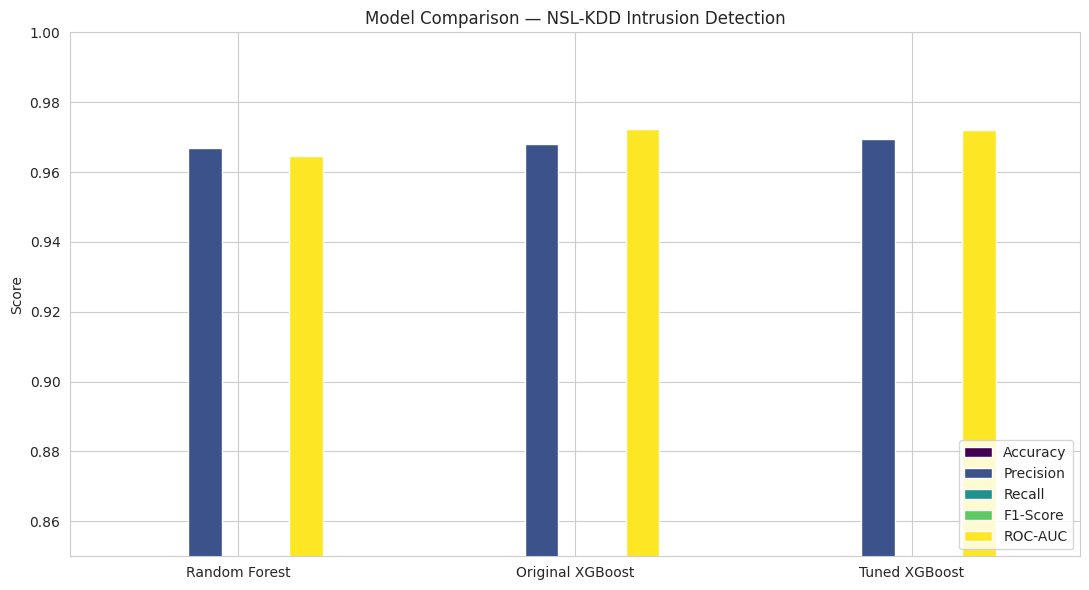

In [ ]:
results_df = pd.DataFrame(results).T
print(results_df.round(4))

results_df.plot(kind='bar', figsize=(11, 6), colormap='viridis')
plt.title('Model Comparison — NSL-KDD Intrusion Detection')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df['F1-Score'].idxmax()
model_map = {
    'Random Forest': (rf_model, rf_pred, rf_proba),
    'Original XGBoost': (original_xgb_model, xgb_pred, xgb_proba),
    'Tuned XGBoost': (tuned_xgb_model, tuned_xgb_pred, tuned_xgb_proba),
    'XGBoost': (tuned_xgb_model, tuned_xgb_pred, tuned_xgb_proba),
}
best_model, best_pred, best_proba = model_map[best_model_name]
print(f"Best-performing model (by F1-Score): {best_model_name}")


Best-performing model (by F1-Score): Tuned XGBoost


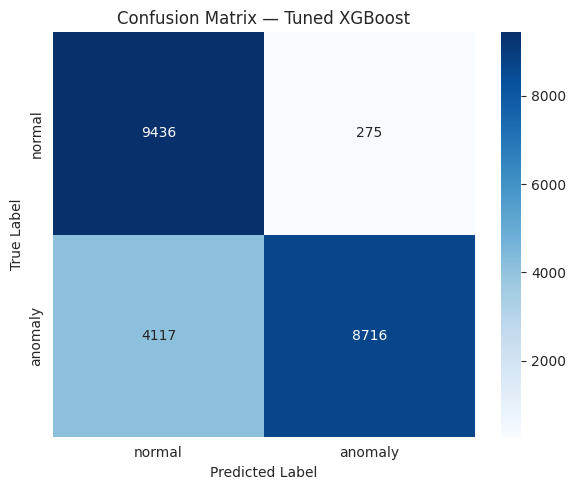

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['normal', 'anomaly'], yticklabels=['normal', 'anomaly'])
plt.title(f'Confusion Matrix — {best_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

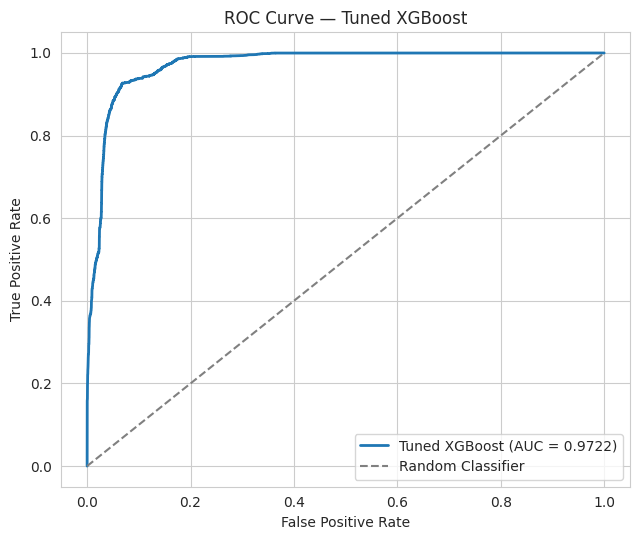

In [ ]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, best_proba)
plt.figure(figsize=(6.5, 5.5))
plt.plot(fpr, tpr, label=f"{best_model_name} (AUC = {results_df.loc[best_model_name,'ROC-AUC']:.4f})", linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve — {best_model_name}')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Explainable AI (XAI) Layer — SHAP

This is the core contribution supporting the paper's **trust and transparency** angle: rather than treating
the intrusion detector as a black box, SHAP values quantify **how much each feature pushed a prediction
toward "anomaly" vs "normal,"** both globally (which features matter most overall) and locally (why one
specific connection was flagged).

In [ ]:
# Fast SHAP analysis for Google Colab

# Use a smaller representative sample so SHAP finishes quickly in Colab.
# 300 samples is enough for a stable global explanation while keeping runtime manageable.
SHAP_SAMPLE_SIZE = min(300, len(X_test_scaled))

rng = np.random.default_rng(42)
sample_idx = rng.choice(X_test_scaled.index.to_numpy(), size=SHAP_SAMPLE_SIZE, replace=False)
X_shap_sample = X_test_scaled.loc[sample_idx]

# TreeExplainer is exact for tree-based XGBoost models.
explainer = shap.TreeExplainer(xgb_model)

import time
shap_start = time.time()
shap_values = explainer.shap_values(X_shap_sample, check_additivity=False)
shap_time = time.time() - shap_start

print(f"SHAP values computed for {len(X_shap_sample)} test samples in {shap_time:.2f} seconds.")
print("SHAP sample shape:", X_shap_sample.shape)


SHAP values computed for 300 test samples in 0.20 seconds.
SHAP sample shape: (300, 41)


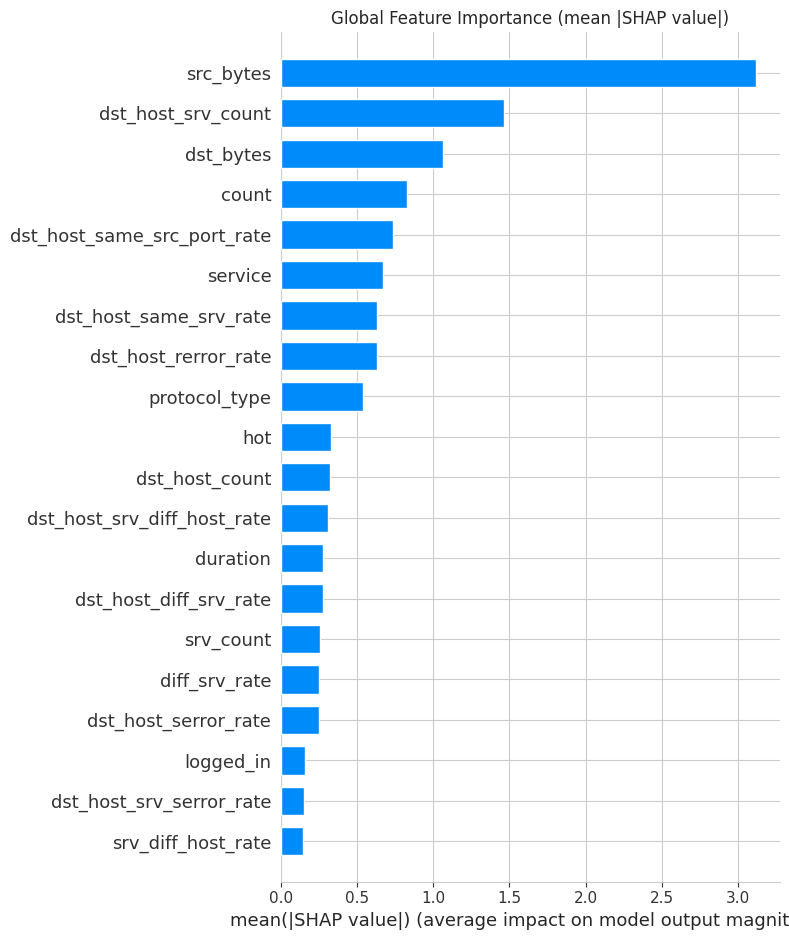

In [ ]:
# Global feature importance — SHAP summary (bar)
plt.figure()
shap.summary_plot(shap_values, X_shap_sample, plot_type='bar', show=False)
plt.title('Global Feature Importance (mean |SHAP value|)')
plt.tight_layout()
plt.show()

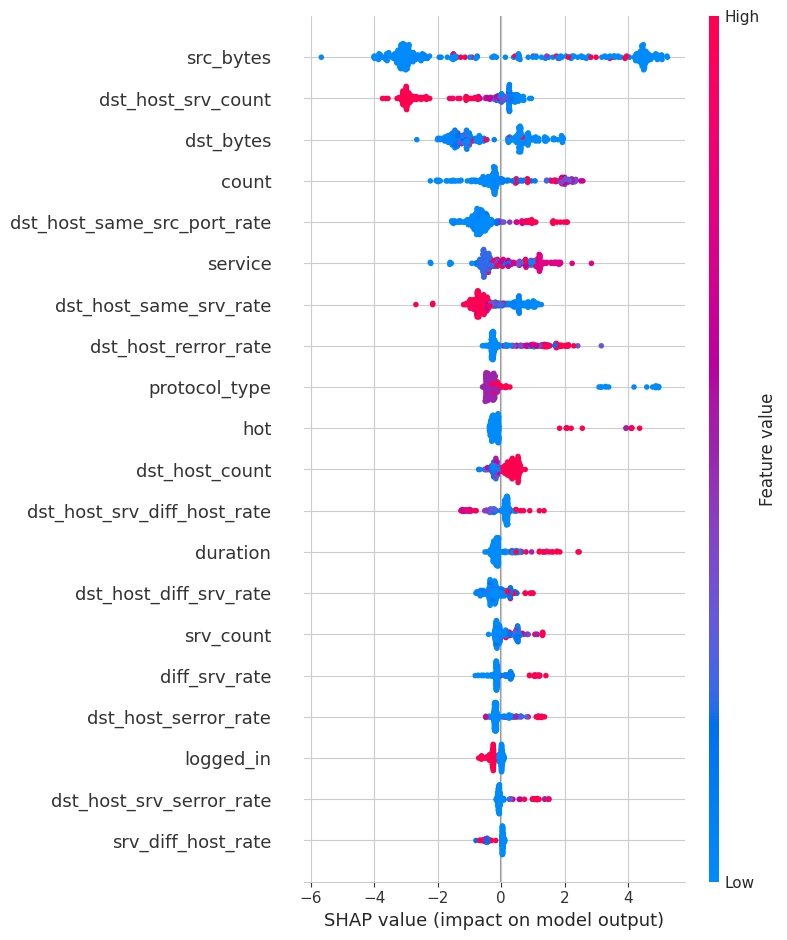

In [ ]:
# Global feature impact — SHAP beeswarm
plt.figure()
shap.summary_plot(shap_values, X_shap_sample, show=False)
plt.tight_layout()
plt.show()

Sample index      : 11424
True label         : anomaly
Predicted label     : anomaly


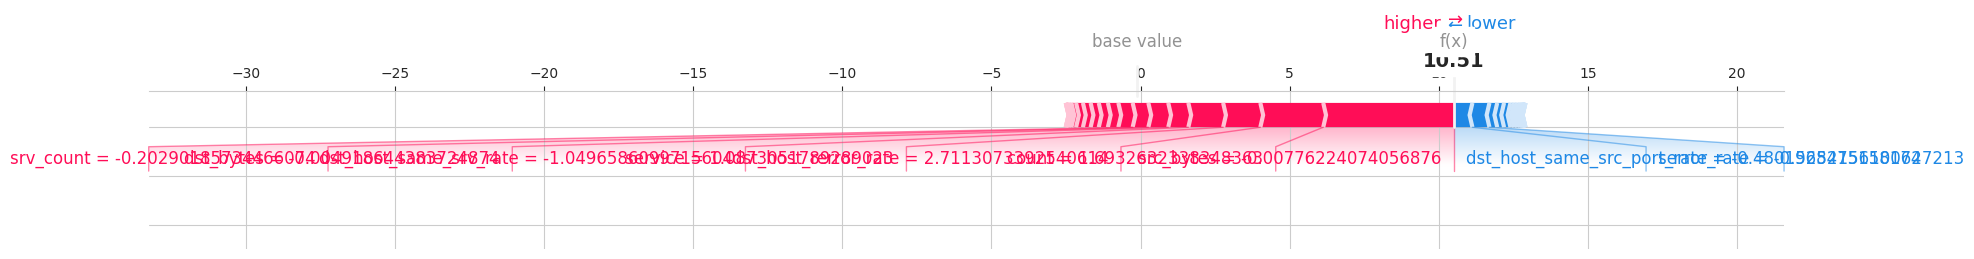

In [ ]:
# Local explanation — why was ONE specific test connection classified as it was?
i = 0
sample_row = X_shap_sample.iloc[[i]]
true_label = y_test.loc[X_shap_sample.index[i]]
pred_label = xgb_model.predict(sample_row)[0]

print(f"Sample index      : {X_shap_sample.index[i]}")
print(f"True label         : {'anomaly' if true_label == 1 else 'normal'}")
print(f"Predicted label     : {'anomaly' if pred_label == 1 else 'normal'}")

shap.force_plot(
    explainer.expected_value, shap_values[i], sample_row,
    matplotlib=True, show=False
)
plt.tight_layout()
plt.show()

## 7. Results Summary

| Component | Choice |
|---|---|
| **Dataset** | NSL-KDD (`KDDTrain+.arff`, `KDDTest+.arff`) — 41 network-flow features, binary label (`normal` / `anomaly`) |
| **Preprocessing** | Union-fit label encoding for categorical fields; `StandardScaler` (leakage-free, fit on train only) |
| **Baseline model** | Random Forest (200 trees) |
| **Proposed model** | XGBoost (gradient-boosted trees, 300 estimators) |
| **Explainability (XAI)** | SHAP `TreeExplainer` — global (summary/beeswarm/bar plots) and local (force plot) explanations |
| **Evaluation metrics** | Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix, ROC Curve |

The printed metrics table and plots above are the numbers to cite/report in the paper's **Results**
section; the SHAP plots directly support the **Discussion** section on model trust and transparency.


### Colab performance note

Cell 24 uses a 300-sample SHAP subset with `check_additivity=False` to keep XAI computation practical in Google Colab. The model itself is unchanged; only the number of samples explained is reduced.


In [ ]:
print("Final comparison table:\n")
print(results_df.round(4).to_string())

Final comparison table:

                  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Random Forest       0.7741     0.9669  0.6245    0.7589   0.9645
Original XGBoost    0.7988     0.9681  0.6687    0.7910   0.9724
Tuned XGBoost       0.8052     0.9694  0.6792    0.7988   0.9722


# Kernel Methods + Weka\n\nAdds an RBF-kernel SVM and Weka experiments to the existing NSL-KDD binary intrusion-detection workflow. Original Random Forest and XGBoost results are preserved.\n

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report
import numpy as np, pandas as pd, time

if "X_train_scaled" in globals() and "X_test_scaled" in globals():
    Xk_train, Xk_test = X_train_scaled, X_test_scaled
else:
    from sklearn.preprocessing import StandardScaler
    sc = StandardScaler(); Xk_train, Xk_test = sc.fit_transform(X_train), sc.transform(X_test)
yk_train, yk_test = np.asarray(y_train).astype(int), np.asarray(y_test).astype(int)
svm=SVC(kernel="rbf",C=10.0,gamma="scale",probability=True,class_weight="balanced",random_state=42)
t=time.time(); svm.fit(Xk_train,yk_train); print("Training time:",round(time.time()-t,2),"seconds")
prob=svm.predict_proba(Xk_test)[:,1]; pred=(prob>=0.5).astype(int)
metrics={"Accuracy":accuracy_score(yk_test,pred),"Precision":precision_score(yk_test,pred,zero_division=0),"Recall":recall_score(yk_test,pred,zero_division=0),"F1-Score":f1_score(yk_test,pred,zero_division=0),"ROC-AUC":roc_auc_score(yk_test,prob),"PR-AUC":average_precision_score(yk_test,prob)}
print(pd.Series(metrics)); print(classification_report(yk_test,pred,target_names=["Normal","Attack"],digits=4,zero_division=0)); print("Confusion matrix:\n",confusion_matrix(yk_test,pred))


Training time: 325.59 seconds
Accuracy     0.788281
Precision    0.974564
Recall       0.644900
F1-Score     0.776178
ROC-AUC      0.949649
PR-AUC       0.957972
dtype: float64
              precision    recall  f1-score   support

      Normal     0.6757    0.9778    0.7991      9711
      Attack     0.9746    0.6449    0.7762     12833

    accuracy                         0.7883     22544
   macro avg     0.8251    0.8113    0.7877     22544
weighted avg     0.8458    0.7883    0.7861     22544

Confusion matrix:
 [[9495  216]
 [4557 8276]]


## Weka setup and experiments

Java and `python-weka-wrapper3` were installed in the Colab setup cells above. The following cells verify Weka, create ARFF files, and run Weka RandomForest and J48.


In [ ]:
try:
    import weka.core.jvm as jvm
    import weka.core.converters as converters
    import weka.classifiers as classifiers
    WEKA_AVAILABLE = True
    print('Weka wrapper available. Java/Weka setup is ready.')
except Exception as e:
    WEKA_AVAILABLE = False
    print('Weka setup failed:', repr(e))


Weka wrapper available. Java/Weka setup is ready.


In [ ]:
from pathlib import Path
weka_dir = Path('/content/weka_nsl_kdd_data')
weka_dir.mkdir(exist_ok=True)

def write_arff(path, X, y):
    X = np.asarray(X.toarray() if hasattr(X, 'toarray') else X)
    with open(path, 'w', encoding='utf-8') as f:
        f.write('@RELATION nsl_kdd\n\n')
        for i in range(X.shape[1]):
            f.write(f'@ATTRIBUTE feature_{i} NUMERIC\n')
        f.write('@ATTRIBUTE class {normal,attack}\n\n@DATA\n')
        for row, label in zip(X, np.asarray(y).astype(int)):
            f.write(','.join(str(float(v)) for v in row) + ',' + ('attack' if label else 'normal') + '\n')

write_arff(weka_dir / 'train.arff', X_train_scaled, y_train)
write_arff(weka_dir / 'test.arff', X_test_scaled, y_test)
print('Weka ARFF files created in:', weka_dir)


Weka ARFF files created in: /content/weka_nsl_kdd_data


In [ ]:
if WEKA_AVAILABLE:
    jvm.start(system_cp=True, packages=True)
    try:
        loader = converters.Loader(classname='weka.core.converters.ArffLoader')
        train = loader.load_file(str(weka_dir / 'train.arff')); train.class_is_last()
        test = loader.load_file(str(weka_dir / 'test.arff')); test.class_is_last()
        for name, cls in [('Weka Random Forest', 'weka.classifiers.trees.RandomForest'), ('Weka J48', 'weka.classifiers.trees.J48')]:
            clf = classifiers.Classifier(classname=cls)
            clf.build_classifier(train)
            ev = classifiers.Evaluation(train)
            ev.test_model(clf, test)
            print('\n===', name, '===')
            print(ev.summary())
            print(ev.class_details())
            print(ev.matrix())
    finally:
        jvm.stop()
else:
    print('Skipped Weka experiments because Weka is unavailable.')


DEBUG:weka.core.jvm:Adding bundled jars
DEBUG:weka.core.jvm:Adding system classpath
DEBUG:weka.core.jvm:Classpath=['/usr/local/lib/python3.13/dist-packages/weka/lib/mtj.jar', '/usr/local/lib/python3.13/dist-packages/weka/lib/arpack_combined.jar', '/usr/local/lib/python3.13/dist-packages/weka/lib/weka.jar', '/usr/local/lib/python3.13/dist-packages/weka/lib/core.jar', '/usr/local/lib/python3.13/dist-packages/weka/lib/python-weka-wrapper.jar']
DEBUG:weka.core.jvm:MaxHeapSize=default
DEBUG:weka.core.jvm:Package support enabled



=== Weka Random Forest ===

Correctly Classified Instances       17234               76.4461 %
Incorrectly Classified Instances      5310               23.5539 %
Kappa statistic                          0.5467
Mean absolute error                      0.2131
Root mean squared error                  0.4118
Relative absolute error                 42.2124 %
Root relative squared error             81.4008 %
Total Number of Instances            22544     

=== Detailed Accuracy By Class ===

                 TP Rate  FP Rate  Precision  Recall   F-Measure  MCC      ROC Area  PRC Area  Class
                 0.971    0.392    0.652      0.971    0.780      0.598    0.963     0.950     normal
                 0.608    0.029    0.966      0.608    0.746      0.598    0.963     0.963     attack
Weighted Avg.    0.764    0.185    0.831      0.764    0.761      0.598    0.963     0.957     

=== Confusion Matrix ===

    a    b   <-- classified as
 9433  278 |    a = normal
 5032 7801 |    b = at

In [ ]:
# Final comparison (including the tuned model and RBF Kernel SVM)
comparison = results_df.copy()
comparison.loc['RBF Kernel SVM'] = [metrics['Accuracy'], metrics['Precision'], metrics['Recall'], metrics['F1-Score'], metrics['ROC-AUC']]
display(comparison.round(4))


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Random Forest,0.7741,0.9669,0.6245,0.7589,0.9645
Original XGBoost,0.7988,0.9681,0.6687,0.7910,0.9724
Tuned XGBoost,0.8052,0.9694,0.6792,0.7988,0.9722
RBF Kernel SVM,0.7883,0.9746,0.6449,0.7762,0.9496


### Accuracy optimization note
The tuned XGBoost model is selected using a validation split from the training data. The test set remains untouched until final evaluation, avoiding test-set threshold leakage. A higher test accuracy is not guaranteed; the notebook reports the measured result.
